In [1]:
import numpy as np
from numpy.polynomial import chebyshev as cheb
from scipy import optimize
import matplotlib.pyplot as plt
from tqdm import tqdm
import matplotlib as mpl
import matplotlib.cm as cm
from scipy.ndimage import zoom, gaussian_filter

# Force Modell

In [2]:
Lp = 1.5 # um Persistence length
kbT = 1

In [3]:
def x_entropic_force(Fe):
    return 1 / np.tanh(2 * Lp * Fe / kbT) - kbT / (2 * Lp * Fe)

def dx_entropic_force(Fe):
    return 1 / (2 * Lp * Fe**2 / kbT) - 2 * Lp / kbT / np.sinh(2 * Lp * Fe / kbT)**2

In [4]:
def create_F(k, sample_density_x=1e-3, n_iter_equalize=5, x_max_full=5, cheb_subsampling = 16):
    
    ''' Creates a force curve for a given w.
        We return a chebychev polynomial that
        approximates the entire curve.

        From the experimental force rate w:
        k = w / v
    '''

    # Find F*, the transition from entropic to hookean force.
    res = optimize.root_scalar(lambda fe: dx_entropic_force(fe) - 1/k, bracket=(1e-12, 30))
    F_star = res.root

    # Determine the x range for forces to occur between 0 and F*
    x_min = x_entropic_force(sample_density_x)
    x_max = x_entropic_force(F_star)

    # Construct an even x grid of forces using the derivative of x
    n_x = max(int((x_max - x_min) / sample_density_x), 2)
    F  = np.linspace(1e-12, F_star, n_x)
    for _ in range(n_iter_equalize):
        cdx = np.cumsum(1/dx_entropic_force(F))
        cdx = cdx - cdx[0]
        cdx = cdx / cdx[-1]
        F = cdx * (F_star) + sample_density_x
    x = x_entropic_force(F)

    # The Hookean tail
    hook_tail_length = x_max_full - x_max
    xh = np.linspace(sample_density_x, hook_tail_length, int((hook_tail_length - sample_density_x) / sample_density_x))
    Fh = k * xh + F[-1]

    x = np.concatenate(([0], x, xh + x[-1]))
    F = np.concatenate(([0], F, Fh))

    C = cheb.Chebyshev.fit(x, F, len(x)//cheb_subsampling)
    
    return C, x, F

100%|████████████████████████████████████████████████████████████████| 30/30 [00:05<00:00,  5.22it/s]


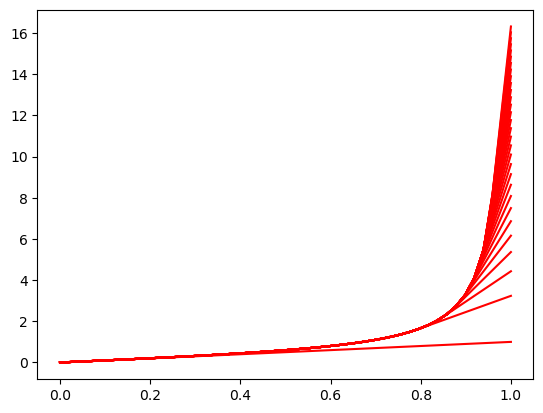

In [5]:
for k in tqdm(np.linspace(1, 200, 30)):
    C, x, F = create_F(k)
    x = np.linspace(0, 1)
    plt.plot(x, C(x), 'r')

# Simulate Trajectories

In [6]:
def sim(C, ru0, xu, v=0.2, dt=1e-2):
    t = 0
    ft = [C(t*v)]
    while True:
        assert v*t < 2
        pu = np.clip(dt * ru0 * np.exp(C(v*t)*xu), 0, 1)
        if pu > np.random.rand(1):
            break
        ft.append(C(v*t))
        t += dt

    return np.array(ft)

Text(0, 0.5, 'F')

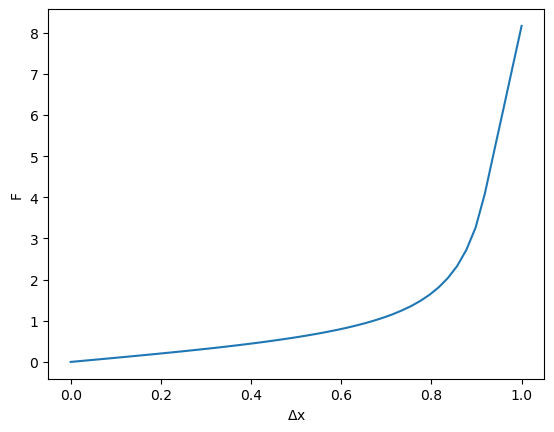

In [7]:
C, x, F = create_F(50)
x = np.linspace(0, 1)
F = C(x)
plt.plot(x,F)
plt.xlabel("$\Delta$x")
plt.ylabel("F")

# Simulate Trajectories

100%|██████████████████████████████████████████████████████████████| 300/300 [00:03<00:00, 81.57it/s]


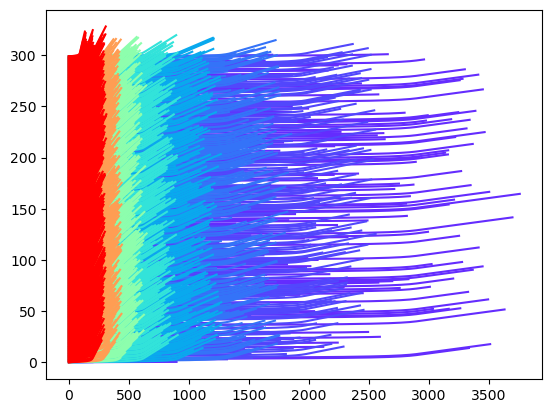

In [8]:
Fs_fast = []
Fs_slow = []

# Run this cell multiple times to generate more data

ru0_GT = 0.05
xu_GT = 0.2

Fs_sets = []

vmin = 0.01
vmax = 0.4

for v in np.logspace(-1.5, 0, 10):
    Fs = []
    for _ in tqdm(range(300)):
        F = sim(C, ru0_GT, xu_GT, v=v)
        Fs.append(F)
    Fs_sets.append((v, Fs))

norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
cmap = cm.ScalarMappable(norm=norm, cmap=cm.rainbow)

for v, Fs in Fs_sets:
    for i, f in enumerate(Fs):
        plt.plot(f+i, color=cmap.to_rgba(v))


# Inference

In [9]:
use = 1

In [10]:
def likelihood(Fs, xu, ru0, dt=1e-2):

    global pbar

    ''' Unnormalized logarithmic likelihood of the force curve
        under parameter xu and ru0. This does not include the
        time step, which scales the likelihood exponentially. '''

    logp = 0
    

    for F in Fs:
        N = len(F)
    
        F_stay_bound  = F[:-1]
        F_unbind      = F[-1]

        with np.errstate(divide='ignore'):
            logp_stay_bound  = np.log(1 - np.clip(dt * ru0 * np.exp(F_stay_bound * xu), 0, 1))
            logp_unbind = np.log(dt * ru0 * np.exp(F_unbind * xu))
            logp += np.sum(logp_unbind) + np.sum(logp_stay_bound)

    pbar.update(1)
    return logp



resolution = 100
cutoff  = 500


#F_run = Fs[:use]
#F_run = Fs
LOGP_sets = []
for v, F_run in Fs_sets:
    #F_run = [f[cutoff:] for f in Fs if len(f) > cutoff]
    #print("Using", len(F_run))
    
    with tqdm(total=resolution**2) as pbar:
        vecfun = np.vectorize(lambda xu, ru0: likelihood(F_run, xu, ru0))
        xu_max = xu_GT * 2.2
        ru0_max = ru0_GT * 2.2
        xu = np.linspace(0, xu_max, resolution)
        ru0 = np.linspace(0, ru0_max, resolution)
        RU0, XU = np.meshgrid(ru0, xu)
        LOGP = vecfun(XU, RU0)
    
    LOGP -= LOGP.max()
    LOGP_sets.append((v, LOGP))

10001it [01:05, 151.67it/s]                                                                          
10001it [01:03, 157.98it/s]                                                                          
10001it [00:57, 172.64it/s]                                                                          
10001it [00:52, 189.43it/s]                                                                          
10001it [00:48, 205.16it/s]                                                                          
10001it [00:44, 224.18it/s]                                                                          
10001it [00:41, 240.71it/s]                                                                          
10001it [00:39, 254.42it/s]                                                                          
10001it [00:38, 261.51it/s]                                                                          
10001it [00:36, 272.56it/s]                                                       

# Plotting

ValueError: Unable to determine Axes to steal space for Colorbar. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.

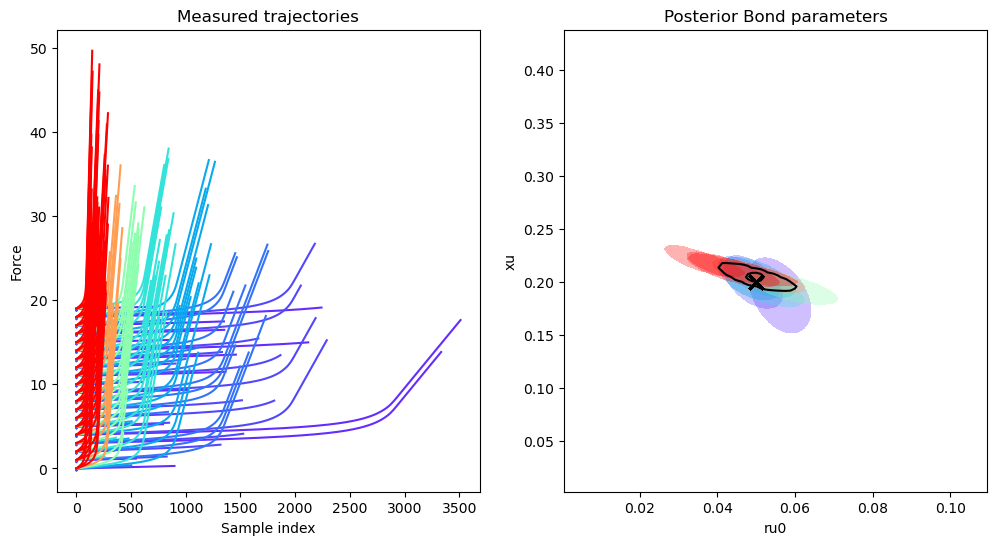

In [11]:
plt.figure(figsize=(12,6))
plt.subplot(1, 2, 1)
for v, Fs in Fs_sets:
    for i, f in enumerate(Fs[:20]):
        plt.plot(f+i, color=cmap.to_rgba(v))

plt.title("Measured trajectories")
plt.xlabel("Sample index")
plt.ylabel("Force")

plt.subplot(1, 2, 2)

for v, LOGP in LOGP_sets:
    P = np.exp(LOGP)
    P_flat = np.sort(P.flatten())
    CDF = np.cumsum(P_flat)
    CDF = CDF / CDF[-1]
    perc = 90
    idx = np.argmax(CDF > (100 - perc)/100)
    
    plt.plot([ru0_GT],[xu_GT], 'kx', markersize=10, markeredgewidth=2)
    
    #plt.imshow(P, origin='lower', extent=(0, ru0_max, 0, xu_max), aspect='auto', cmap='ocean_r', alpha=0.3)
    plt.contourf(gaussian_filter(zoom(P, 1), 1), origin='lower', extent=(0, ru0_max, 0, xu_max), levels=[P_flat[idx], 1], alpha=0.3, linestyles='-', colors=[cmap.to_rgba(v)])
    plt.title(f"Posterior Bond parameters")
    plt.xlabel("ru0")
    plt.ylabel("xu")
    PRU0 = np.sum(P, axis=0)
    PRU0 /= np.sum(PRU0)
    #plt.plot(ru0, PRU0, 'teal')
    #plt.fill_between(ru0, PRU0, color='teal')
    PXU = np.sum(P, axis=1)
    PXU /= np.sum(PXU)
    #plt.axvline(np.sum(ru0 * PRU0), color='g', linestyle='-', alpha=0.4)
    #plt.plot(PXU*0.1, xu, 'teal')
    #plt.fill_betweenx(xu, PXU*0.1, color='teal')
    #plt.axhline(np.sum(xu * PXU), color='g', linestyle='-', alpha=0.4)
#plt.savefig(f"img/seq{use}.png", dpi=300)
#plt.close()
#use += 1

mean_LOGP = sum([LOGP for v, LOGP in LOGP_sets])
mean_LOGP -= mean_LOGP.max()
mean_LOGP /= len(LOGP_sets)
P = np.exp(mean_LOGP)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
idx = np.argmax(CDF > (100 - perc)/100)
plt.plot([ru0_GT],[xu_GT], 'kx', markersize=10, markeredgewidth=2)
CS = plt.contour(gaussian_filter(zoom(P, 1), 0), origin='lower', extent=(0, ru0_max, 0, xu_max), levels=[P_flat[idx],], alpha=1, linestyles=['-'], colors=['k'])

mean_LOGP = sum([LOGP for v, LOGP in LOGP_sets])
mean_LOGP -= mean_LOGP.max()
#mean_LOGP /= len(LOGP_sets)
P = np.exp(mean_LOGP)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
idx = np.argmax(CDF > (100 - perc)/100)
plt.plot([ru0_GT],[xu_GT], 'kx', markersize=10, markeredgewidth=2)
CS = plt.contour(gaussian_filter(zoom(P, 1), 0), origin='lower', extent=(0, ru0_max, 0, xu_max), levels=[P_flat[idx],], alpha=1, linestyles=['-'], colors=['k'])


cmappable = cm.ScalarMappable(norm=norm, cmap=cm.rainbow)
plt.colorbar(cmappable, label='Drag velocity v')

#plt.legend()

plt.savefig("da_figure.png", dpi=300)